In [2]:
import pandas as pd
import numpy as np

# Load cleaned dataset
df = pd.read_csv("data/processed/cleaned_data.csv")

# Convert date columns
df["transaction_date"] = pd.to_datetime(df["transaction_date"])
df["expiration_date"] = pd.to_datetime(df["expiration_date"])

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (100000, 42)


In [3]:
# Inspect inventory-related columns
inventory_columns = [
    "product_name",
    "category",
    "initial_quantity",
    "daily_demand",
    "units_sold",
    "units_wasted",
    "expiration_date",
    "days_remaining_at_purchase"
]

print(df[inventory_columns].head(10).to_string(index=False))

  product_name        category  initial_quantity  daily_demand  units_sold  units_wasted expiration_date  days_remaining_at_purchase
        Donuts          Bakery               158            54         138            20      2024-09-29                           4
      Sausages            Meat               353            55         251           102      2023-04-21                           7
        Bagels          Bakery               483           331         483             0      2024-10-27                           2
      Vaccines Pharmaceuticals               477             7         477             0      2024-02-17                          80
   Fresh Pasta    Ready_to_Eat               391           169         391             0      2023-08-09                           3
     Eye Drops Pharmaceuticals               270             0           0           270      2025-07-06                         319
   Fresh Juice       Beverages                42             4       

In [4]:
# Check whether sales + waste equals initial quantity
df["sales_plus_waste"] = (
    df["units_sold"] + df["units_wasted"]
)

df["inventory_difference"] = (
    df["initial_quantity"] - df["sales_plus_waste"]
)

print("Sales + Waste vs Initial Quantity")
print(df["inventory_difference"].describe())

print(
    "\nRecords where sales + waste equals initial quantity:",
    (df["inventory_difference"] == 0).sum()
)

print(
    "\nRecords where sales + waste exceeds initial quantity:",
    (df["inventory_difference"] < 0).sum()
)

print(
    "\nRecords where sales + waste is below initial quantity:",
    (df["inventory_difference"] > 0).sum()
)

Sales + Waste vs Initial Quantity
count    100000.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
Name: inventory_difference, dtype: float64

Records where sales + waste equals initial quantity: 100000

Records where sales + waste exceeds initial quantity: 0

Records where sales + waste is below initial quantity: 0


In [5]:
print("Demand vs Units Sold")

print(
    "Demand greater than sales:",
    (df["daily_demand"] > df["units_sold"]).sum()
)

print(
    "Demand equal to sales:",
    (df["daily_demand"] == df["units_sold"]).sum()
)

print(
    "Demand lower than sales:",
    (df["daily_demand"] < df["units_sold"]).sum()
)

Demand vs Units Sold
Demand greater than sales: 4091
Demand equal to sales: 7790
Demand lower than sales: 88119


In [6]:
# Records where demand exceeds sales
shortage_candidates = df[
    df["daily_demand"] > df["units_sold"]
].copy()

print("Potential shortage records:",
      len(shortage_candidates))

print("\nAverage values:")
print(
    shortage_candidates[
        ["initial_quantity", "daily_demand",
         "units_sold", "units_wasted"]
    ].mean().round(2)
)

print("\nSample records:")
print(
    shortage_candidates[
        ["product_name", "category", "initial_quantity",
         "daily_demand", "units_sold", "units_wasted"]
    ].head(15).to_string(index=False)
)

Potential shortage records: 4091

Average values:
initial_quantity    254.60
daily_demand        313.97
units_sold          212.55
units_wasted         42.05
dtype: float64

Sample records:
product_name     category  initial_quantity  daily_demand  units_sold  units_wasted
       Sushi Ready_to_Eat               277           360         193            84
        Tuna      Seafood               481           394         360           121
      Salmon      Seafood               171           196         171             0
        Crab      Seafood               228           233         228             0
      Shrimp      Seafood               292           241         204            88
  Sandwiches Ready_to_Eat               409           534         286           123
 Fresh Pasta Ready_to_Eat               452           483         316           136
       Wraps Ready_to_Eat               379           582         379             0
       Wraps Ready_to_Eat               445           

In [7]:
# Check how many potential shortage records had zero waste
print(
    "Zero-waste records:",
    (shortage_candidates["units_wasted"] == 0).sum()
)

print(
    "Records with waste:",
    (shortage_candidates["units_wasted"] > 0).sum()
)

Zero-waste records: 1974
Records with waste: 2117


In [8]:
# Category-level inventory analysis

category_inventory = df.groupby("category").agg(
    Records=("record_id", "count"),
    Average_Initial_Quantity=("initial_quantity", "mean"),
    Average_Demand=("daily_demand", "mean"),
    Average_Units_Sold=("units_sold", "mean"),
    Average_Units_Wasted=("units_wasted", "mean"),
    Demand_Gap_Records=(
        "daily_demand",
        lambda x: (x > df.loc[x.index, "units_sold"]).sum()
    )
)

category_inventory["Demand_Gap_Percentage"] = (
    category_inventory["Demand_Gap_Records"]
    / category_inventory["Records"] * 100
)

print(category_inventory.round(2))


                 Records  Average_Initial_Quantity  Average_Demand  \
category                                                             
Bakery             10039                    253.25          114.32   
Beverages           9901                    253.34           24.15   
Dairy               9964                    253.84           29.39   
Deli                9991                    256.93           59.38   
Frozen_Meals        9923                    254.68            1.64   
Meat               10055                    256.12           73.30   
Pharmaceuticals    10120                    254.74            1.91   
Produce            10001                    255.48           44.77   
Ready_to_Eat       10049                    256.07          186.41   
Seafood             9957                    254.05          108.76   

                 Average_Units_Sold  Average_Units_Wasted  Demand_Gap_Records  \
category                                                                      

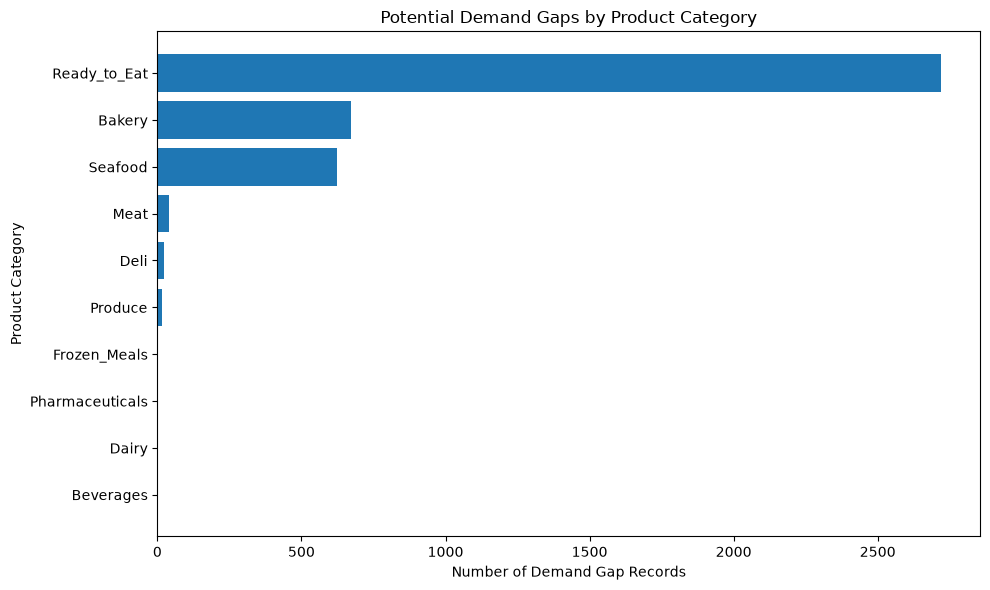

In [9]:
import matplotlib.pyplot as plt

category_plot = category_inventory.sort_values(
    "Demand_Gap_Records",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    category_plot.index,
    category_plot["Demand_Gap_Records"]
)

plt.xlabel("Number of Demand Gap Records")
plt.ylabel("Product Category")
plt.title("Potential Demand Gaps by Product Category")

plt.tight_layout()
plt.show()

In [10]:
# Calculate remaining inventory
df["remaining_inventory"] = (
    df["initial_quantity"]
    - df["units_sold"]
    - df["units_wasted"]
)

print("Remaining inventory statistics:")
print(df["remaining_inventory"].describe())

print(
    "\nRecords with remaining inventory:",
    (df["remaining_inventory"] > 0).sum()
)

print(
    "\nRecords with zero remaining inventory:",
    (df["remaining_inventory"] == 0).sum()
)

Remaining inventory statistics:
count    100000.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
Name: remaining_inventory, dtype: float64

Records with remaining inventory: 0

Records with zero remaining inventory: 100000


In [11]:
# Create a simple inventory recommendation function

def inventory_recommendation(predicted_demand, available_stock):

    shortage = max(0, predicted_demand - available_stock)

    if shortage > 0:
        status = "Reorder Required"
    else:
        status = "Stock Sufficient"

    return {
        "Predicted Demand": round(predicted_demand, 2),
        "Available Stock": available_stock,
        "Potential Shortage": round(shortage, 2),
        "Suggested Reorder": round(shortage, 2),
        "Status": status
    }


# Example scenario
result = inventory_recommendation(
    predicted_demand=120,
    available_stock=80
)

print(result)

{'Predicted Demand': 120, 'Available Stock': 80, 'Potential Shortage': 40, 'Suggested Reorder': 40, 'Status': 'Reorder Required'}


In [14]:
import os
os.makedirs("models", exist_ok=True)

In [15]:
import os

print(os.listdir("models"))

['random_forest_baseline.pkl']


In [16]:
import joblib

pipeline = joblib.load("models/random_forest_baseline.pkl")

print("Random Forest pipeline loaded successfully!")

Random Forest pipeline loaded successfully!


In [18]:
import os

print("Current directory:")
print(os.getcwd())

print("\nFiles and folders in current directory:")
print(os.listdir())

print("\nChecking parent directory:")
print(os.listdir(".."))

Current directory:
d:\M_tech\sem 3\BDA\Freshflow\notebooks

Files and folders in current directory:
['01_EDA.ipynb', '01_eda_Analysis.ipynb', '02_PCA_Analysis.ipynb', '03_Random_Forest.ipynb', '04_Inventory_Recommendations.ipynb', 'chat.py', 'data', 'models', 'results']

Checking parent directory:
['.venv', 'app.py', 'data', 'notebooks', 'outputs', 'src']


In [19]:
import os

paths = [
    "data/processed/cleaned_data.csv",
    "../data/processed/cleaned_data.csv"
]

for path in paths:
    print(path, "->", os.path.exists(path))
    

data/processed/cleaned_data.csv -> True
../data/processed/cleaned_data.csv -> False


In [20]:
import pandas as pd
import numpy as np

df = pd.read_csv("data/processed/cleaned_data.csv")

df["transaction_date"] = pd.to_datetime(df["transaction_date"])
df["expiration_date"] = pd.to_datetime(df["expiration_date"])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (100000, 42)


In [21]:
# Get the exact features expected by the trained model
feature_columns = pipeline.feature_names_in_

# Select one historical record
sample = df.iloc[[0]].copy()

# Prepare model input
X_sample = sample[list(feature_columns)]

# Predict demand
predicted_demand = pipeline.predict(X_sample)[0]

print("Product:", sample["product_name"].iloc[0])
print("Actual Demand:", sample["daily_demand"].iloc[0])
print("Predicted Demand:", round(predicted_demand, 2))

Product: Donuts
Actual Demand: 54
Predicted Demand: 70.66


In [22]:
# Inventory recommendation function
def inventory_recommendation(predicted_demand, available_stock):

    shortage = max(0, predicted_demand - available_stock)

    return {
        "Predicted Demand": round(predicted_demand, 2),
        "Available Stock": available_stock,
        "Potential Shortage": round(shortage, 2),
        "Suggested Reorder": int(np.ceil(shortage)),
        "Status": "Reorder Required" if shortage > 0 else "Stock Sufficient"
    }


# Example: user-provided available stock
available_stock = 60

result = inventory_recommendation(
    predicted_demand=predicted_demand,
    available_stock=available_stock
)

print("INVENTORY RECOMMENDATION")
for key, value in result.items():
    print(f"{key}: {value}")

INVENTORY RECOMMENDATION
Predicted Demand: 70.66
Available Stock: 60
Potential Shortage: 10.66
Suggested Reorder: 11
Status: Reorder Required


In [23]:
print("Days remaining at purchase:")
print(df["days_remaining_at_purchase"].describe())

print("\nShelf life:")
print(df["shelf_life_days"].describe())

print("\nDays until expiry:")
print(df["days_until_expiry"].describe())

Days remaining at purchase:
count    100000.000000
mean         56.114940
std         118.160892
min           0.000000
25%           4.000000
50%           8.000000
75%          20.000000
max         723.000000
Name: days_remaining_at_purchase, dtype: float64

Shelf life:
count    100000.000000
mean         67.169300
std         140.550322
min           1.000000
25%           5.000000
50%           9.000000
75%          24.000000
max         730.000000
Name: shelf_life_days, dtype: float64

Days until expiry:
count    100000.00000
mean         54.67519
std         118.13746
min           0.00000
25%           3.00000
50%           6.00000
75%          19.00000
max         720.00000
Name: days_until_expiry, dtype: float64


In [24]:
expiry_analysis = (
    df.groupby("category")
    .agg(
        total_records=("record_id", "count"),
        avg_shelf_life=("shelf_life_days", "mean"),
        median_shelf_life=("shelf_life_days", "median"),
        avg_days_remaining=("days_remaining_at_purchase", "mean"),
        median_days_remaining=("days_remaining_at_purchase", "median"),
        avg_waste_pct=("waste_pct", "mean"),
        total_units_wasted=("units_wasted", "sum")
    )
    .round(2)
    .sort_values("avg_days_remaining")
)

display(expiry_analysis)

,total_records,avg_shelf_life,median_shelf_life,avg_days_remaining,median_days_remaining,avg_waste_pct,total_units_wasted
category,,,,,,,
Ready_to_Eat,10049,3.03,3.0,2.54,3.0,14.56,359091
Bakery,10039,4.50,4.0,3.83,4.0,15.35,365116
Seafood,9957,4.52,5.0,3.84,4.0,17.41,410919
Meat,10055,6.49,6.0,5.56,5.0,18.20,423986
Deli,9991,8.54,9.0,7.28,7.0,16.90,375593
Produce,10001,11.99,12.0,10.14,10.0,18.45,400822
Dairy,9964,17.46,17.0,14.71,14.0,16.91,332290
Beverages,9901,18.48,18.0,15.60,15.0,20.70,418323
Frozen_Meals,9923,212.30,212.0,177.24,175.0,50.01,1167759


In [25]:
def classify_expiry_risk(days_remaining):

    if days_remaining <= 3:
        return "Critical"

    elif days_remaining <= 7:
        return "High"

    elif days_remaining <= 14:
        return "Moderate"

    else:
        return "Low"


df["expiry_risk"] = df["days_remaining_at_purchase"].apply(
    classify_expiry_risk
)

print("Expiry Risk Distribution:")
print(df["expiry_risk"].value_counts())

print("\nExpiry Risk by Category:")
display(
    pd.crosstab(
        df["category"],
        df["expiry_risk"],
        normalize="index"
    ).mul(100).round(2)
)

Expiry Risk Distribution:
expiry_risk
Low         32490
High        30234
Critical    19207
Moderate    18069
Name: count, dtype: int64

Expiry Risk by Category:


expiry_risk,Critical,High,Low,Moderate
category,,,,
Bakery,41.68,58.32,0.00,0.00
Beverages,0.00,9.83,54.34,35.83
Dairy,0.00,17.13,49.42,33.45
Deli,12.58,39.85,0.00,47.57
Frozen_Meals,0.00,0.00,100.00,0.00
Meat,18.86,61.47,0.00,19.67
Pharmaceuticals,0.00,0.00,100.00,0.00
Produce,8.30,25.71,21.43,44.57
Ready_to_Eat,69.12,30.88,0.00,0.00


In [27]:
def combined_inventory_recommendation(
    predicted_demand,
    available_stock,
    days_remaining
):
    shortage = max(0, predicted_demand - available_stock)

    expiry_risk = classify_expiry_risk(days_remaining)

    if shortage > 0 and expiry_risk in ["Critical", "High"]:
        status = "Review Replenishment + Expiry"
        action = "Check existing stock before ordering"

    elif shortage > 0:
        status = "Reorder Required"
        action = "Consider replenishing the shortage"

    elif expiry_risk in ["Critical", "High"]:
        status = "Expiry Risk"
        action = "Prioritize existing stock for sale"

    else:
        status = "Stock Sufficient"
        action = "Continue monitoring inventory"

    return {
        "Predicted Demand": round(predicted_demand, 2),
        "Available Stock": available_stock,
        "Potential Shortage": round(shortage, 2),
        "Potential Reorder Quantity": int(np.ceil(shortage)),
        "Days Remaining": days_remaining,
        "Expiry Risk": expiry_risk,
        "Final Status": status,
        "Recommended Action": action
    }


result = combined_inventory_recommendation(
    predicted_demand=predicted_demand,
    available_stock=60,
    days_remaining=3
)

for key, value in result.items():
    print(f"{key}: {value}")

Predicted Demand: 70.66
Available Stock: 60
Potential Shortage: 10.66
Potential Reorder Quantity: 11
Days Remaining: 3
Expiry Risk: Critical
Final Status: Review Replenishment + Expiry
Recommended Action: Check existing stock before ordering


In [28]:
import sys
sys.path.append("..")

from src.recommendations import combined_inventory_recommendation

test_result = combined_inventory_recommendation(
    predicted_demand=70.66,
    available_stock=60,
    days_remaining=3
)

print(test_result)

{'Predicted Demand': 70.66, 'Available Stock': 60, 'Potential Shortage': 10.66, 'Potential Reorder Quantity': 11, 'Days Remaining': 3, 'Expiry Risk': 'Critical', 'Final Status': 'Review Replenishment + Expiry', 'Recommended Action': 'Check existing stock before ordering'}
